# PID Control: Structure, Implementation and Anti-Windup

`03_pid` | level 1 | experiment id(s): `exp_03_pid_implementation`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 4 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Write the discrete PID law in positional form and explain each term, including derivative on
  measurement, a filtered derivative, setpoint weighting and bumpless transfer.
- Verify a PID implementation against an independent discrete-time model (`scipy.signal.dlsim`)
  to better than 1e-9, and against closed-form checks of each term.
- Measure the effect of anti-windup, derivative filtering and setpoint weighting on overshoot,
  IAE, control effort and saturation time.

## 2. Real-World Engineering Problem

Most industrial loops are PI or PID: motor speed, tank level, temperature, pressure. In real
plants the actuator saturates (valve fully open, voltage at the supply limit) and the
sensor is noisy. A textbook PID without anti-windup overshoots badly after a saturating
transient, and a PID with unfiltered derivative turns sensor noise into actuator chatter. These
are the failures the implementation details below prevent.

## 3. Research Background

The three-term controller was formalised in pneumatic instruments in the 1930s and 1940s, with
Ziegler and Nichols (1942) giving the first widely used tuning rules. Practical refinements
(derivative filter, setpoint weighting, integrator anti-windup, bumpless transfer) are
documented in Astrom and Hagglund (1995). Section 4 lists what was verified.

## 4. Research Literature

The two books below are the sources for the structure and the anti-windup methods. They are
cited for method; no numerical result is copied from them.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| am2021 | Astrom, K. J.; Murray, R. M. (2021). Feedback Systems: An Introduction for Scientists and Engineers, 2nd ed.. Princeton University Press. ISBN 978-0-691-19398-4. | Modern introduction to feedback, modeling, stability, PID and robustness. | Broad textbook; industrial specifics are limited. | verified (2026-11-25, web search of publisher/index/library record). Library record gives publisher, year and ISBN. |
| zn1942 | Ziegler, J. G.; Nichols, N. B. (1942). Optimum settings for automatic controllers. Transactions of the ASME, 64, 759-768. | Origin of the open-loop (reaction curve) and closed-loop (ultimate gain) PID rules. | Tuned for a pneumatic controller and quarter-amplitude decay; the loops are often oscillatory by modern criteria. | verified (2026-11-25, web search of publisher/index/library record). Facsimile of the paper and several citation lists agree on volume and pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Continuous law (parallel form, physical gains) with error $e=r-y$:
$$u=K_p(br-y)+K_i\int_0^te\,d\tau-K_d\frac{dy}{dt}+u_{ff}.$$
Units: $K_p$ in input/output units, $K_i=K_p/T_i$ in input/(output s), $K_d=K_pT_d$ in
input s/output units, $b\in[0,1]$ the proportional setpoint weight (dimensionless).

**Discretisation (sampling time $T_s$).**
- Integral (forward Euler): $I_k=I_{k-1}+K_iT_se_k$.
- Derivative on measurement with a first-order filter of time constant $T_f$:
  $D_k=\dfrac{T_f}{T_f+T_s}D_{k-1}-\dfrac{K_d}{T_f+T_s}(y_k-y_{k-1})$.
  For a unit step in $y$ with $D_{k-1}=0$ this gives $D=-K_d/(T_f+T_s)$ immediately.
- Saturation: $u=\min(\max(u_{unsat},u_{min}),u_{max})$.

**Anti-windup by back-calculation.** $I_k\leftarrow I_k+\dfrac{T_s}{T_t}(u-u_{unsat})$, with
tracking time constant $T_t$ (here $T_t=K_p/K_i=T_i$). **Clamping:** do not integrate while
saturated and the error drives the output further into saturation.

## 6. System Modeling

Plant for all experiments: FOPDT `K = 1`, `T = 5 s`, `L = 1 s`, `Ts = 0.05 s` (exact ZOH
discretisation, integer-sample delay). Actuator limits `[0, 1.5]` where saturation is wanted.
The input disturbance is added to the plant input. These are illustrative values.

## 7. Dataset and Measurement Data

No dataset. All signals are simulated, and sensor noise is white Gaussian noise from a seeded
generator.

## 8. Algorithm Architecture

```
r --> [b] --+--> (+) --> Kp ------------------+
            |                                 v
y --------> (-) --> e --> Ki*Ts --> I(z) --> (+) --> sat --> u --> plant --> y
 |                                     ^                |
 +--> -Kd*d/dt (filtered, on y) -------+                |
                  back-calculation  (u - u_unsat)/Tt ---+
```

## 9. Algorithm Implementation

Pseudocode (one sample):
```
e = r - y
P = Kp*(b*r - y)
D = Tf/(Tf+Ts)*D - Kd/(Tf+Ts)*(y - y_prev)
I_new = I + Ki*Ts*e
u_unsat = P + I_new + D + u_ff
u = clip(u_unsat, u_min, u_max)
I = I_new + (Ts/Tt)*(u - u_unsat)          # back-calculation
```
The cell below first writes the naive from-scratch version (derivative on error, no filter, no
anti-windup) so the effect of each refinement can be measured against it.

In [2]:
from control_lab.controllers import PID
from control_lab.controllers.tuning import imc_pid
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.metrics import iae, step_response_metrics, total_variation, saturation_fraction
from control_lab.models import FOPDTPlant
from control_lab.signals import white_noise
from control_lab.simulation import run_closed_loop

EXP = "exp_03_pid_implementation"
K, T, L, Ts = 1.0, 5.0, 1.0, 0.05

class NaivePID:
    """Textbook discretisation: derivative on error, no filter, no saturation awareness."""
    def __init__(self, kp, ki, kd, Ts, u_min=-np.inf, u_max=np.inf):
        self.kp, self.ki, self.kd, self.Ts, self.lo, self.hi = kp, ki, kd, Ts, u_min, u_max
        self.reset()
    def reset(self):
        self.i, self.e_prev = 0.0, None
    def update(self, r, y):
        e = r - y
        d = 0.0 if self.e_prev is None else (e - self.e_prev) / self.Ts
        self.e_prev = e
        self.i += self.ki * self.Ts * e
        return float(np.clip(self.kp * e + self.i + self.kd * d, self.lo, self.hi))

g = imc_pid(K, T, L, lam=1.5, kind="PID")
gpi = imc_pid(K, T, L, lam=1.5, kind="PI")
print({k: round(v, 3) for k, v in g.items()}, {k: round(v, 3) for k, v in gpi.items()})

def plant():
    return FOPDTPlant(K, T, L, Ts)

{'kp': 2.75, 'ti': 5.5, 'td': 0.455} {'kp': 2.0, 'ti': 5.0, 'td': 0.0}


## 10. Simulation and Numerical Analysis

Scenarios (all `Ts = 0.05 s`): (A) P, PI and PID with IMC-based gains (`lambda = 1.5 s`):
unit setpoint step at 0 s and a 0.3 input disturbance at 40 s. (B) Setpoint step with the naive and
the library PID to expose derivative kick. (C) Setpoint 2.0 for 30 s (unreachable with
`u <= 1.5`), then 1.0, with no anti-windup, clamping and back-calculation. (D) Sensor noise
(std 0.01) with derivative filter `Tf` in {0.05, 0.25, 1.0} s. (E) Setpoint weight `b` in
{1, 0.6, 0.3}.

## 11. Experimental Validation

Level: **software simulation**. The independent reference is a discrete-time linear model solved
with `scipy.signal.dlsim`, plus closed-form checks of individual terms. There is no
controller-in-the-loop or hardware test, so scan-time jitter, ADC quantisation and actuator
dynamics are not covered.

## 12. Performance Evaluation

In [3]:
checks, metrics = [], {}
n = int(80 / Ts)
t = np.arange(n) * Ts
ref = np.ones(n)
dist = np.where(t >= 40.0, 0.3, 0.0)

# (A) P, PI, PID
res = {}
for name, ctl in {"P": PID(kp=gpi["kp"], Ts=Ts),
                  "PI": PID.from_times(gpi["kp"], gpi["ti"], 0.0, Ts=Ts),
                  "PID": PID.from_times(g["kp"], g["ti"], g["td"], Ts=Ts, tf=0.1 * g["td"] + 1e-9)}.items():
    o = run_closed_loop(plant(), ctl, ref, Ts, disturbance=dist)
    m = step_response_metrics(t[: int(40 / Ts)], o["y"][: int(40 / Ts)], 1.0)
    res[name] = {"overshoot_percent": m["overshoot_percent"], "settling_time": m["settling_time"],
                 "steady_state_error_before_disturbance": m["steady_state_error"],
                 "iae_total": iae(t, o["e"]), "final_error": float(1.0 - o["y"][-1])}
    res[name]["_y"] = o["y"]
metrics["P_PI_PID"] = {k: {a: b for a, b in v.items() if a != "_y"} for k, v in res.items()}
checks.append(check("P offset equals 1/(1+Kc K)", abs(res["P"]["steady_state_error_before_disturbance"]
               - 1 / (1 + gpi["kp"] * K)) < 2e-3, f"{res['P']['steady_state_error_before_disturbance']:.4f}"))
checks.append(check("integral action removes offset (PI, PID)",
                    abs(res["PI"]["final_error"]) < 2e-3 and abs(res["PID"]["final_error"]) < 2e-3,
                    f"PI {res['PI']['final_error']:.1e}, PID {res['PID']['final_error']:.1e} after the disturbance"))

# independent discrete model (L = 0) for a PI loop
kp_, ti_ = 1.5, 4.0
ki_ = kp_ / ti_
a = np.exp(-Ts / T); b_ = K * (1 - a)
A = np.array([[a - b_ * (kp_ + ki_ * Ts), b_], [-ki_ * Ts, 1.0]])
B = np.array([[b_ * (kp_ + ki_ * Ts)], [ki_ * Ts]])
from scipy.signal import dlsim
_, y_ref, _ = dlsim((A, B, np.array([[1.0, 0.0]]), np.zeros((1, 1)), Ts), np.ones((n, 1)))
o = run_closed_loop(FOPDTPlant(K, T, 0.0, Ts), PID.from_times(kp_, ti_, 0.0, Ts=Ts), np.ones(n), Ts)
err = float(np.max(np.abs(o["y"] - y_ref[:, 0])))
metrics["dlsim_reference"] = {"max_abs_difference": err}
checks.append(check("PI loop equals scipy dlsim of the closed-loop state model", err < 1e-9, f"max |diff| = {err:.1e}"))

# term-level checks
c = PID(kp=2.0, ki=0.0, kd=0.0, Ts=Ts)
checks.append(check("P term", abs(c.update(1.0, 0.25) - 1.5) < 1e-12, "u = Kp (r - y)"))
c = PID(kp=0.0, ki=0.0, kd=1.0, Ts=Ts, tf=0.2); c.update(0.0, 0.0)
d0 = c.update(0.0, 1.0)
checks.append(check("derivative filter first-sample value -Kd dy/(Tf+Ts)", abs(d0 + 1.0 / (0.2 + Ts)) < 1e-12, f"{d0:.4f}"))
c = PID(kp=1.0, ki=0.5, kd=0.0, Ts=Ts); c.update(1.0, 0.2)
c.track(0.7, 1.0, 0.2); u_next = c.update(1.0, 0.2)
checks.append(check("bumpless transfer (output continues from manual value + I step)", abs(u_next - (0.7 + 0.5 * Ts * 0.8)) < 1e-12, f"{u_next:.6f}"))

# (B) derivative kick: the setpoint steps at 5 s, after the loop has settled at zero
tt = np.arange(int(15 / Ts)) * Ts
r_k = np.where(tt >= 5.0, 1.0, 0.0)
kick = {}
for name, ctl in {"naive (derivative on error)": NaivePID(g["kp"], g["kp"] / g["ti"], g["kp"] * g["td"], Ts),
                  "library (derivative on measurement, filtered)": PID.from_times(g["kp"], g["ti"], g["td"], Ts=Ts, tf=0.1 * g["td"] + 1e-9)}.items():
    o = run_closed_loop(plant(), ctl, r_k, Ts)
    kick[name] = {"largest_one_sample_change_in_u": float(np.max(np.abs(np.diff(o["u"])))),
                  "u_peak": float(o["u"].max())}
metrics["derivative_kick"] = kick
names = list(kick)
j0, j1 = (kick[n_]["largest_one_sample_change_in_u"] for n_ in names)
checks.append(check("derivative on measurement removes the setpoint kick", j1 < 0.5 * j0,
                    f"largest one-sample change in u: naive {j0:.2f}, library {j1:.2f} "
                    f"(expected naive about Kp+Kd/Ts = {g['kp'] + g['kp'] * g['td'] / Ts:.2f}, library about Kp = {g['kp']:.2f})"))

# (C) windup
nw = int(120 / Ts); tw = np.arange(nw) * Ts
rw = np.where(tw < 30.0, 2.0, 1.0)
wind = {}
outs_w = {}
i30 = int(30 / Ts)
for mode in ("none", "clamp", "backcalc"):
    ctl = PID.from_times(gpi["kp"], gpi["ti"], 0.0, Ts=Ts, u_min=0.0, u_max=1.5, antiwindup=mode)
    o = run_closed_loop(plant(), ctl, rw, Ts)
    after = o["y"][i30:]
    outside = np.flatnonzero(np.abs(after - 1.0) > 0.02)
    recovery = float((outside[-1] + 1) * Ts) if outside.size else 0.0  # last time outside the 2 % band
    wind[mode] = {"recovery_time_to_2pct_band_s": recovery,
                  "undershoot_below_setpoint": float(max(0.0, 1.0 - after.min())),
                  "iae_after_return": float(iae(tw[i30:], 1.0 - after)),
                  "saturated_fraction": float(saturation_fraction(o["u"], 0.0, 1.5))}
    outs_w[mode] = o
metrics["windup"] = wind
checks.append(check("anti-windup shortens recovery after saturation",
                    wind["backcalc"]["recovery_time_to_2pct_band_s"] < 0.5 * wind["none"]["recovery_time_to_2pct_band_s"]
                    and wind["clamp"]["recovery_time_to_2pct_band_s"] < 0.5 * wind["none"]["recovery_time_to_2pct_band_s"],
                    "recovery time [s]: " + ", ".join(f"{k}={v['recovery_time_to_2pct_band_s']:.1f}" for k, v in wind.items())))

# (D) noise and derivative filter
nn = int(60 / Ts); tn_ = np.arange(nn) * Ts
noisy = {}
outs_n = {}
for tf in (0.05, 0.25, 1.0):
    ctl = PID.from_times(g["kp"], g["ti"], g["td"], Ts=Ts, tf=tf)
    o = run_closed_loop(plant(), ctl, np.ones(nn), Ts, noise_std=0.01, seed=7)
    noisy[str(tf)] = {"total_variation_u": float(total_variation(o["u"][int(20 / Ts):])),
                      "iae": float(iae(tn_, o["e"]))}
    outs_n[tf] = o
metrics["derivative_filter_noise"] = noisy
tv = [noisy[k]["total_variation_u"] for k in ("0.05", "0.25", "1.0")]
checks.append(check("longer derivative filter lowers control activity under noise", tv[0] > tv[1] > tv[2],
                    f"TV(u) = {tv[0]:.2f}, {tv[1]:.2f}, {tv[2]:.2f}"))

# (E) setpoint weight
wt = {}
outs_b = {}
for bw in (1.0, 0.6, 0.3):
    ctl = PID.from_times(gpi["kp"], gpi["ti"], 0.0, Ts=Ts, b=bw)
    o = run_closed_loop(plant(), ctl, ref, Ts, disturbance=dist)
    m = step_response_metrics(t[: int(40 / Ts)], o["y"][: int(40 / Ts)], 1.0)
    wt[str(bw)] = {"overshoot_percent": m["overshoot_percent"], "rise_time_10_90": m["rise_time_10_90"]}
    outs_b[bw] = o
metrics["setpoint_weight"] = wt
same = np.max(np.abs(outs_b[1.0]["y"][int(40 / Ts) + 400:] - outs_b[0.3]["y"][int(40 / Ts) + 400:]))
checks.append(check("setpoint weight does not change the disturbance response (late window)", same < 5e-3, f"max diff {same:.1e}"))
for c_ in checks:
    print("PASS" if c_["passed"] else "FAIL", c_["name"], "|", c_["detail"])

PASS P offset equals 1/(1+Kc K) | 0.3333
PASS integral action removes offset (PI, PID) | PI -9.0e-05, PID -7.3e-05 after the disturbance
PASS PI loop equals scipy dlsim of the closed-loop state model | max |diff| = 3.3e-15
PASS P term | u = Kp (r - y)
PASS derivative filter first-sample value -Kd dy/(Tf+Ts) | -4.0000
PASS bumpless transfer (output continues from manual value + I step) | 0.720000
PASS derivative on measurement removes the setpoint kick | largest one-sample change in u: naive 27.77, library 2.77 (expected naive about Kp+Kd/Ts = 27.75, library about Kp = 2.75)
PASS anti-windup shortens recovery after saturation | recovery time [s]: none=54.4, clamp=17.6, backcalc=4.7
PASS longer derivative filter lowers control activity under noise | TV(u) = 164.71, 62.99, 34.32
PASS setpoint weight does not change the disturbance response (late window) | max diff 7.8e-06


Each check compares the implementation with an independent reference or with a closed-form value
derived in section 5. The three behavioural checks (derivative kick, anti-windup, derivative
filter) compare variants of the same controller, so they test the claim about the variant, not
the numerics.

## 13. Visualization and Interpretation

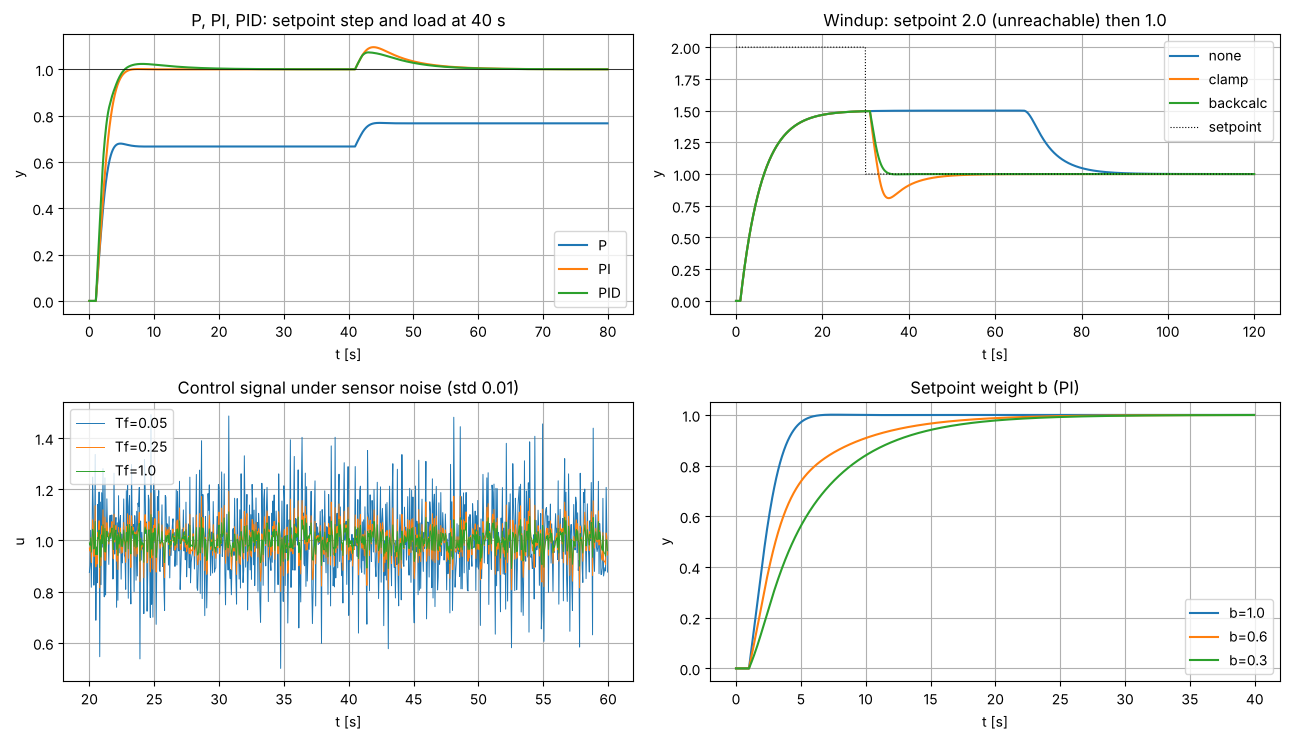

          recovery_time_to_2pct_band_s  undershoot_below_setpoint  \
none                             54.35                      0.000   
clamp                            17.55                      0.190   
backcalc                          4.65                      0.003   

          iae_after_return  saturated_fraction  
none                21.502               0.546  
clamp                2.385               0.250  
backcalc             1.225               0.250  
      total_variation_u    iae
0.05            164.710  2.448
0.25             62.993  2.433
1.0              34.325  2.396


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
for k, v in res.items():
    ax[0, 0].plot(t, v["_y"], label=k)
ax[0, 0].axhline(1, color="k", lw=0.5); ax[0, 0].set(title="P, PI, PID: setpoint step and load at 40 s", xlabel="t [s]", ylabel="y"); ax[0, 0].legend()
for k, o in outs_w.items():
    ax[0, 1].plot(tw, o["y"], label=k)
ax[0, 1].plot(tw, rw, "k:", lw=0.8, label="setpoint")
ax[0, 1].set(title="Windup: setpoint 2.0 (unreachable) then 1.0", xlabel="t [s]", ylabel="y"); ax[0, 1].legend()
for tf, o in outs_n.items():
    ax[1, 0].plot(tn_[int(20 / Ts):], o["u"][int(20 / Ts):], lw=0.7, label=f"Tf={tf}")
ax[1, 0].set(title="Control signal under sensor noise (std 0.01)", xlabel="t [s]", ylabel="u"); ax[1, 0].legend()
for bw, o in outs_b.items():
    ax[1, 1].plot(t[: int(40 / Ts)], o["y"][: int(40 / Ts)], label=f"b={bw}")
ax[1, 1].set(title="Setpoint weight b (PI)", xlabel="t [s]", ylabel="y"); ax[1, 1].legend()
fig.tight_layout()
figs = [save_figure(fig, EXP, "pid_implementation")]
plt.show()
import pandas as pd
print(pd.DataFrame(metrics["windup"]).T.round(3))
print(pd.DataFrame(metrics["derivative_filter_noise"]).T.round(3))

Top left: the P loop keeps a permanent offset; PI and PID remove it, including after the
disturbance. Top right: without anti-windup the integrator charges during the 30 s the output is
saturated, so after the setpoint returns to 1.0 the output stays pinned near 1.5 while the
integrator discharges; the printed table gives the recovery time and IAE. Clamping stops the worst of the windup
(recovery 17.6 s against 54.4 s) but leaves an undershoot of 0.19 below the setpoint;
back-calculation recovers in 4.7 s with an undershoot below 0.01 for this plant. Bottom left: a short derivative filter passes the noise to the actuator. Bottom right:
reducing `b` lowers the setpoint overshoot at the price of a slower rise, with no effect on
disturbance rejection.

## 14. Research Discussion and Limitations

**Advantages.** Three parameters, no plant model needed at run time, well understood.
**Limits.** (1) Derivative action amplifies noise unless filtered, and the right filter time is a
trade-off with phase lead. (2) Anti-windup needs a tracking time constant; back-calculation
with `Tt = Ti` is a common default, not an optimum. (3) The gains here come from an IMC rule on
a known FOPDT, so the loop performance depends on the model used (see notebooks 02 and 04).
(4) Forward-Euler integration is accurate only if `Ts` is small relative to `Ti`. (5) Timing,
ADC resolution and actuator dynamics of a real controller are not modelled.

## 15. Summary, Exercises, and Further Research

**Key insights.** The structure details (derivative on measurement, filter, anti-windup) matter
as much as the gains.

**Exercises.** (1) Add a rate limit to the actuator and re-run (C). (2) Replace forward Euler by
trapezoidal integration and compare the dlsim difference. (3) Choose `Tt` by sweeping and plot
overshoot against `Tt/Ti`.

**Related.** PID tuning (notebook 04), DC motor speed control (06), fuzzy PI (08).
**Research directions.** Two-degree-of-freedom structures, event-based PID, and
data-driven tuning.

In [5]:
rec = ExperimentRecord(
    experiment_id=EXP, title="PID structure and implementation effects",
    notebook="notebooks/02_classical/03_pid.ipynb", algorithm="Discrete PID with filtered derivative and anti-windup",
    application="Generic FOPDT loop (illustrative)", plant_model="FOPDT K=1, T=5 s, L=1 s",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated plant; seeded sensor noise."},
    metrics=metrics, checks=checks, sampling_time_s=Ts, random_seed=7, number_of_trials=1,
    controller_parameters={"IMC lambda_s": 1.5, "PID": g, "PI": gpi, "u_limits": [0.0, 1.5]},
    plant_parameters={"K": K, "T_s": T, "L_s": L}, input_configuration={"setpoint": "step 1.0; 2.0 then 1.0 (windup case)"},
    disturbance_configuration={"input_step": 0.3, "sensor_noise_std": 0.01},
    operating_conditions={"saturation": "[0, 1.5] in the windup scenario"}, figure_references=figs,
    limitations=["One plant and one noise seed; the trends are not a general ranking.",
                 "Forward-Euler integrator; no scan-time jitter or quantisation.",
                 "No hardware or controller-in-the-loop validation."])
print(rec.save())

experiments/results/exp_03_pid_implementation.json
